In [16]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Reproducibility
np.random.seed(42)

# Load the existing cleaned jobs dataset
jobs = pd.read_csv("../data/processed/jobs_cleaned.csv")

# Convert extracted skills into Python lists
jobs['technical_skills'] = jobs['technical_skills'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

jobs['professional_skills'] = jobs['professional_skills'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

print("Jobs loaded successfully!")
print("Dataset shape:", jobs.shape)

jobs[['id', 'title', 'company', 'employment_type',
      'workplace_type', 'technical_skills']].head()

Jobs loaded successfully!
Dataset shape: (1020, 13)


,id,title,company,employment_type,workplace_type,technical_skills
0,1,Machine Learning Engineering Internship - Summer 2026,Viant Technology,Internship,Hybrid,"[python, sql, machine learning, artificial intelligence, data science, data pipelines, tensorflo..."
1,2,NVIDIA 2026 Internships: Deep Learning Computer Architecture - US,NVIDIA,Full-time,On-site,"[python, c++, deep learning, neural networks, tensorflow, pytorch, keras, computer architecture,..."
2,3,Summer 2026 Intern - Undergrad User Research - Slack,Salesforce,Full-time,Hybrid,"[artificial intelligence, statistics]"
3,4,Summer 2026 Engineering Intern,Truveta,Full-time,Hybrid,"[python, java, c#, big data]"
4,5,Applied AI Engineer (Internship),Fortinet,Full-time,On-site,"[python, go, generative ai, cybersecurity]"


In [17]:
career_profiles = {
    "Machine Learning": {
        "skills": [
            "python", "machine learning", "deep learning",
            "tensorflow", "pytorch", "scikit-learn",
            "artificial intelligence", "neural networks"
        ],
        "title_keywords": [
            "machine learning", "ml engineer", "ai engineer",
            "deep learning", "artificial intelligence"
        ]
    },

    "Data Science": {
        "skills": [
            "python", "sql", "data science",
            "data analysis", "statistics", "pandas",
            "numpy", "data visualization", "power bi"
        ],
        "title_keywords": [
            "data scientist", "data analyst", "data engineer",
            "analytics", "business intelligence"
        ]
    },

    "Software Development": {
        "skills": [
            "java", "javascript", "python", "react",
            "html", "css", "c++", "typescript",
            "node.js", "git"
        ],
        "title_keywords": [
            "software engineer", "software developer",
            "full stack", "frontend", "backend",
            "web developer"
        ]
    },

    "Cloud & DevOps": {
        "skills": [
            "aws", "azure", "google cloud", "docker",
            "kubernetes", "linux", "jenkins", "ci/cd"
        ],
        "title_keywords": [
            "cloud engineer", "devops", "infrastructure",
            "platform engineer", "site reliability"
        ]
    },

    "Cybersecurity": {
        "skills": [
            "cybersecurity", "networking", "linux",
            "python", "cloud computing"
        ],
        "title_keywords": [
            "cybersecurity", "security engineer",
            "security analyst", "threat investigator",
            "information security"
        ]
    },

    "Research & AI": {
        "skills": [
            "artificial intelligence", "research",
            "machine learning", "statistics",
            "natural language processing", "python",
            "data analysis"
        ],
        "title_keywords": [
            "research scientist", "research engineer",
            "ai researcher", "research analyst",
            "applied ai"
        ]
    }
}

In [18]:
number_of_users = 4000

career_categories = list(career_profiles.keys())

user_profiles = []

for i in range(1, number_of_users + 1):

    primary_interest = np.random.choice(career_categories)

    # Select a different secondary interest
    secondary_options = [
        category for category in career_categories
        if category != primary_interest
    ]

    secondary_interest = np.random.choice(secondary_options)

    user_profiles.append({
        "user_id": f"USER_{i:03d}",
        "primary_interest": primary_interest,
        "secondary_interest": secondary_interest,
        "preferred_employment": np.random.choice(
            ["Full-time", "Internship", "Contract"],
            p=[0.60, 0.30, 0.10]
        ),
        "preferred_workplace": np.random.choice(
            ["Remote", "Hybrid", "On-site"],
            p=[0.40, 0.35, 0.25]
        )
    })

user_profiles = pd.DataFrame(user_profiles)

print("Total synthetic users:", len(user_profiles))

display(user_profiles.head(10))

print("\nPrimary career interest distribution:")
display(user_profiles['primary_interest'].value_counts())

Total synthetic users: 4000


,user_id,primary_interest,secondary_interest,preferred_employment,preferred_workplace
0,USER_001,Cloud & DevOps,Research & AI,Full-time,On-site
1,USER_002,Cybersecurity,Data Science,Full-time,Remote
2,USER_003,Cybersecurity,Cloud & DevOps,Full-time,Hybrid
3,USER_004,Cybersecurity,Data Science,Internship,On-site
4,USER_005,Data Science,Cybersecurity,Full-time,Remote
5,USER_006,Research & AI,Cybersecurity,Full-time,Remote
6,USER_007,Software Development,Data Science,Full-time,On-site
7,USER_008,Research & AI,Software Development,Full-time,On-site
8,USER_009,Machine Learning,Cloud & DevOps,Internship,Hybrid
9,USER_010,Machine Learning,Software Development,Contract,On-site



Primary career interest distribution:


primary_interest
Cybersecurity           681
Research & AI           677
Data Science            675
Machine Learning        663
Cloud & DevOps          654
Software Development    650
Name: count, dtype: int64

Experience and skill preferences

In [19]:
# Generate individual skill preferences for each user

def generate_user_skills(primary_interest, secondary_interest):

    primary_skills = career_profiles[primary_interest]['skills']
    secondary_skills = career_profiles[secondary_interest]['skills']

    selected_primary = list(
        np.random.choice(
            primary_skills,
            size=min(5, len(primary_skills)),
            replace=False
        )
    )

    selected_secondary = list(
        np.random.choice(
            secondary_skills,
            size=min(2, len(secondary_skills)),
            replace=False
        )
    )

    return list(set(selected_primary + selected_secondary))


user_profiles['preferred_skills'] = user_profiles.apply(
    lambda row: generate_user_skills(
        row['primary_interest'],
        row['secondary_interest']
    ),
    axis=1
)

# Generate experience levels
user_profiles['experience_level'] = np.random.choice(
    ['Entry-level', 'Junior', 'Mid-level', 'Senior'],
    size=len(user_profiles),
    p=[0.35, 0.30, 0.25, 0.10]
)

display(user_profiles.head())

,user_id,primary_interest,secondary_interest,preferred_employment,preferred_workplace,preferred_skills,experience_level
0,USER_001,Cloud & DevOps,Research & AI,Full-time,On-site,"[machine learning, aws, azure, kubernetes, statistics, docker, jenkins]",Junior
1,USER_002,Cybersecurity,Data Science,Full-time,Remote,"[linux, numpy, python, networking, cloud computing, cybersecurity, statistics]",Senior
2,USER_003,Cybersecurity,Cloud & DevOps,Full-time,Hybrid,"[linux, python, networking, cloud computing, kubernetes, cybersecurity, ci/cd]",Entry-level
3,USER_004,Cybersecurity,Data Science,Internship,On-site,"[linux, python, networking, cloud computing, pandas, cybersecurity, statistics]",Senior
4,USER_005,Data Science,Cybersecurity,Full-time,Remote,"[sql, numpy, linux, python, power bi, statistics, data analysis]",Mid-level


Job relevance-scoring engine

In [20]:
# Create a vocabulary of all skills used in career profiles
all_skills = sorted(set(
    skill
    for profile in career_profiles.values()
    for skill in profile['skills']
))

# Create a binary job-skill matrix
job_skill_matrix = np.zeros(
    (len(jobs), len(all_skills)),
    dtype=np.float32
)

for i, skills in enumerate(jobs['technical_skills']):

    for skill in skills:

        if skill in all_skills:
            skill_index = all_skills.index(skill)
            job_skill_matrix[i, skill_index] = 1

print("Job-skill matrix shape:", job_skill_matrix.shape)
print("Unique skills:", len(all_skills))

Job-skill matrix shape: (1020, 38)
Unique skills: 38


In [21]:
# Store relevance scores for every user-job combination
relevance_matrix = np.zeros(
    (len(user_profiles), len(jobs)),
    dtype=np.float32
)

job_titles = jobs['title'].fillna('').str.lower().values

job_employment = (
    jobs['employment_type'].fillna('').str.lower().values
)

job_workplace = (
    jobs['workplace_type'].fillna('').str.lower().values
)

# Create a mapping of skill names to their matrix positions
skill_to_index = {
    skill: index
    for index, skill in enumerate(all_skills)
}

for user_index, user in user_profiles.iterrows():

    primary = career_profiles[user['primary_interest']]
    secondary = career_profiles[user['secondary_interest']]

    # Primary and secondary skill vectors
    primary_indices = [
        skill_to_index[s]
        for s in primary['skills']
        if s in skill_to_index
    ]

    secondary_indices = [
        skill_to_index[s]
        for s in secondary['skills']
        if s in skill_to_index
    ]

    # Calculate skill coverage
    primary_coverage = (
        job_skill_matrix[:, primary_indices].sum(axis=1)
        / max(len(primary_indices), 1)
    )

    secondary_coverage = (
        job_skill_matrix[:, secondary_indices].sum(axis=1)
        / max(len(secondary_indices), 1)
    )

    # Match job titles against career keywords
    primary_title_match = np.array([
        any(keyword in title for keyword in primary['title_keywords'])
        for title in job_titles
    ], dtype=np.float32)

    secondary_title_match = np.array([
        any(keyword in title for keyword in secondary['title_keywords'])
        for title in job_titles
    ], dtype=np.float32)

    # Match employment preferences
    employment_match = (
        job_employment ==
        str(user['preferred_employment']).lower()
    ).astype(np.float32)

    # Match workplace preferences
    workplace_match = (
        job_workplace ==
        str(user['preferred_workplace']).lower()
    ).astype(np.float32)

    # Calculate final relevance score
    relevance_scores = (
        0.55 * primary_coverage +
        0.15 * secondary_coverage +
        0.15 * primary_title_match +
        0.05 * secondary_title_match +
        0.05 * employment_match +
        0.05 * workplace_match
    )

    relevance_matrix[user_index] = relevance_scores

print("Relevance scoring completed!")
print("Relevance matrix shape:", relevance_matrix.shape)

Relevance scoring completed!
Relevance matrix shape: (4000, 1020)


RELEVANCE SCORE DISTRIBUTION
count    4.080000e+06
mean     1.520038e-01
std      1.231430e-01
min      0.000000e+00
25%      5.000000e-02
50%      1.264286e-01
75%      2.100000e-01
max      7.962500e-01
dtype: float64


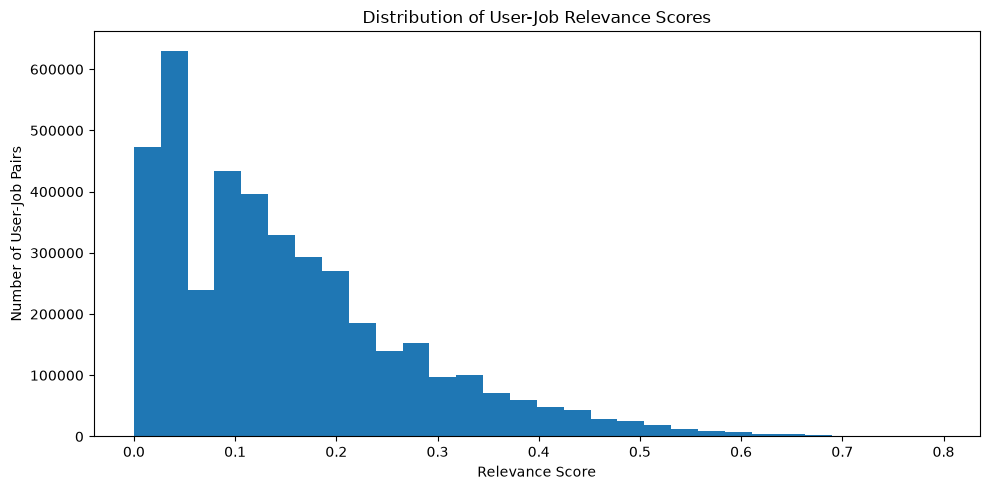

In [22]:
relevance_values = relevance_matrix.flatten()

print("RELEVANCE SCORE DISTRIBUTION")
print("=" * 45)

print(pd.Series(relevance_values).describe())

plt.figure(figsize=(10, 5))

plt.hist(
    relevance_values,
    bins=30
)

plt.title("Distribution of User-Job Relevance Scores")
plt.xlabel("Relevance Score")
plt.ylabel("Number of User-Job Pairs")

plt.tight_layout()
plt.show()

In [23]:
for threshold in [0.30, 0.40, 0.50, 0.60]:

    relevant_counts = (
        relevance_matrix >= threshold
    ).sum(axis=1)

    print(f"\nThreshold: {threshold}")

    print("Average relevant jobs:",
          round(relevant_counts.mean(), 2))

    print("Minimum relevant jobs:",
          relevant_counts.min())

    print("Maximum relevant jobs:",
          relevant_counts.max())


Threshold: 0.3
Average relevant jobs: 128.33
Minimum relevant jobs: 20
Maximum relevant jobs: 526

Threshold: 0.4
Average relevant jobs: 51.09
Minimum relevant jobs: 4
Maximum relevant jobs: 252

Threshold: 0.5
Average relevant jobs: 16.06
Minimum relevant jobs: 0
Maximum relevant jobs: 102

Threshold: 0.6
Average relevant jobs: 4.25
Minimum relevant jobs: 0
Maximum relevant jobs: 24


In [24]:
# Define the relevance threshold
RELEVANCE_THRESHOLD = 0.40

# Convert relevance scores into binary labels
relevance_labels = (
    relevance_matrix >= RELEVANCE_THRESHOLD
).astype(np.int8)

# Check the results
relevant_counts = relevance_labels.sum(axis=1)

print("RELEVANCE LABEL SUMMARY")
print("=" * 45)

print("Total users:", len(user_profiles))
print("Total jobs:", len(jobs))
print("Total relevant user-job pairs:", relevance_labels.sum())
print("Average relevant jobs per user:", relevant_counts.mean())
print("Minimum relevant jobs:", relevant_counts.min())
print("Maximum relevant jobs:", relevant_counts.max())

print("\nLabel distribution:")
print(pd.Series(relevance_labels.flatten()).value_counts())

RELEVANCE LABEL SUMMARY
Total users: 4000
Total jobs: 1020
Total relevant user-job pairs: 204358
Average relevant jobs per user: 51.0895
Minimum relevant jobs: 4
Maximum relevant jobs: 252

Label distribution:
0    3875642
1     204358
Name: count, dtype: int64


In [25]:
# Save the new user profiles
user_profiles.to_csv(
    "../data/processed/user_profiles_v2.csv",
    index=False
)

# Save the relevance scores
np.save(
    "../data/processed/user_job_relevance_v2.npy",
    relevance_matrix
)

# Save the binary relevance labels
np.save(
    "../data/processed/user_job_relevance_labels_v2.npy",
    relevance_labels
)

print("New synthetic data saved successfully!")

New synthetic data saved successfully!


**Generate synthetic user interactions**

In [26]:
# Set random seed for reproducibility
np.random.seed(42)

interactions = []

# Number of jobs each user is exposed to
JOBS_PER_USER = 40

for user_index, user in user_profiles.iterrows():

    # Get relevance scores for this user
    scores = relevance_matrix[user_index]

    # Find jobs with relevance scores above the threshold
    relevant_indices = np.where(
        relevance_labels[user_index] == 1
    )[0]

    # Find jobs below the relevance threshold
    other_indices = np.where(
        relevance_labels[user_index] == 0
    )[0]

    # Select relevant jobs, prioritising higher relevance
    relevant_indices = relevant_indices[
        np.argsort(scores[relevant_indices])[::-1]
    ]

    # Select up to 30 relevant jobs
    relevant_sample_size = min(30, len(relevant_indices))

    selected_relevant = relevant_indices[:relevant_sample_size]

    # Select 10 exploratory jobs from the remaining jobs
    exploration_sample_size = min(
        10, len(other_indices)
    )

    selected_other = np.random.choice(
        other_indices,
        size=exploration_sample_size,
        replace=False
    )

    # Combine selected jobs
    selected_jobs = np.concatenate([
        selected_relevant,
        selected_other
    ])

    # Shuffle job exposure order
    np.random.shuffle(selected_jobs)

    for job_index in selected_jobs:

        relevance = scores[job_index]

        # Probability of viewing increases with relevance
        view_probability = np.clip(
            0.45 + relevance * 0.50,
            0.10,
            0.95
        )

        if np.random.random() > view_probability:
            continue

        # Save probability increases with relevance
        save_probability = np.clip(
            0.10 + relevance * 0.75,
            0.05,
            0.80
        )

        # Apply probability increases with relevance
        apply_probability = np.clip(
            0.02 + relevance * 0.35,
            0.01,
            0.40
        )

        random_value = np.random.random()

        if random_value < apply_probability:
            interaction_type = "apply"
            rating = 5

        elif random_value < apply_probability + save_probability:
            interaction_type = "save"
            rating = 3

        else:
            interaction_type = "view"
            rating = 1

        interactions.append({
            "user_id": user["user_id"],
            "job_id": jobs.iloc[job_index]["id"],
            "interaction_type": interaction_type,
            "rating": rating,
            "relevance_score": relevance,
            "is_relevant": int(
                relevance >= RELEVANCE_THRESHOLD
            )
        })

# Convert to DataFrame
interactions_v2 = pd.DataFrame(interactions)

print("INTERACTION DATASET SUMMARY")
print("=" * 45)

print("Total interactions:", len(interactions_v2))
print("Unique users:", interactions_v2["user_id"].nunique())
print("Unique jobs:", interactions_v2["job_id"].nunique())

print("\nInteraction distribution:")
print(interactions_v2["interaction_type"].value_counts())

print("\nAverage interactions per user:")
print(
    interactions_v2.groupby("user_id")
    .size()
    .describe()
)

display(interactions_v2.head(10))

INTERACTION DATASET SUMMARY
Total interactions: 80224
Unique users: 4000
Unique jobs: 1020

Interaction distribution:
interaction_type
save     33803
view     32650
apply    13771
Name: count, dtype: int64

Average interactions per user:
count    4000.000000
mean       20.056000
std         7.569821
min         3.000000
25%        13.000000
50%        21.000000
75%        27.000000
max        36.000000
dtype: float64


,user_id,job_id,interaction_type,rating,relevance_score,is_relevant
0,USER_001,58,save,3,0.517857,1
1,USER_001,579,save,3,0.465179,1
2,USER_001,214,view,1,0.536607,1
3,USER_001,852,apply,5,0.465179,1
4,USER_001,276,view,1,0.552679,1
5,USER_001,620,view,1,0.486607,1
6,USER_001,378,apply,5,0.533929,1
7,USER_001,711,view,1,0.050000,0
8,USER_001,556,save,3,0.731250,1
9,USER_001,570,view,1,0.483929,1


In [27]:
interactions_v2.to_csv(
    "../data/processed/user_interactions_v2.csv",
    index=False
)

print("New interaction dataset saved successfully!")

New interaction dataset saved successfully!


In [28]:
print("INTERACTION DATASET VALIDATION")
print("=" * 50)

print("\n1. Dataset dimensions:")
print(interactions_v2.shape)

print("\n2. Unique users:")
print(interactions_v2["user_id"].nunique())

print("\n3. Unique jobs:")
print(interactions_v2["job_id"].nunique())

print("\n4. Interaction distribution:")
print(interactions_v2["interaction_type"].value_counts())

print("\n5. Interaction percentages:")
print(
    interactions_v2["interaction_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n6. Interactions per user:")
print(
    interactions_v2.groupby("user_id")
    .size()
    .describe()
)

print("\n7. Relevant vs irrelevant interactions:")
print(
    interactions_v2["is_relevant"]
    .value_counts()
)

print("\n8. Relevance by interaction type:")
print(
    interactions_v2.groupby("interaction_type")[
        "is_relevant"
    ].mean().round(3)
)

print("\n9. Duplicate user-job interactions:")
print(
    interactions_v2.duplicated(
        subset=["user_id", "job_id"]
    ).sum()
)

print("\n10. Missing values:")
print(interactions_v2.isnull().sum())

INTERACTION DATASET VALIDATION

1. Dataset dimensions:
(80224, 6)

2. Unique users:
4000

3. Unique jobs:
1020

4. Interaction distribution:
interaction_type
save     33803
view     32650
apply    13771
Name: count, dtype: int64

5. Interaction percentages:
interaction_type
save     42.14
view     40.70
apply    17.17
Name: proportion, dtype: float64

6. Interactions per user:
count    4000.000000
mean       20.056000
std         7.569821
min         3.000000
25%        13.000000
50%        21.000000
75%        27.000000
max        36.000000
dtype: float64

7. Relevant vs irrelevant interactions:
is_relevant
1    59624
0    20600
Name: count, dtype: int64

8. Relevance by interaction type:
interaction_type
apply    0.887
save     0.876
view     0.546
Name: is_relevant, dtype: float64

9. Duplicate user-job interactions:
0

10. Missing values:
user_id             0
job_id              0
interaction_type    0
rating              0
relevance_score     0
is_relevant         0
dtype: int64
